In [7]:
from matplotlib import pyplot as plt
import numpy as np
import random
import math

#### a) Inverse Distribution formulation and Preparation

Please see the attached pdf for detailed derivation. The derived function is
$x = F^{-1}(y) = (1 - y)^{-2}$

Function used for the following section
$x = F^{-1}(\frac{y}{A}) = (1 - \frac{y}{A})^{-2}$

In [8]:
points = 1000
A = 200000
B = 190000
rand_num_y = np.random.uniform(0, B,1000) # Generate data of 1000 points
x_gen = pow(1 - rand_num_y/A,-2)
NUMBER_OF_BINS = 30


#### b) Linear binning

[]

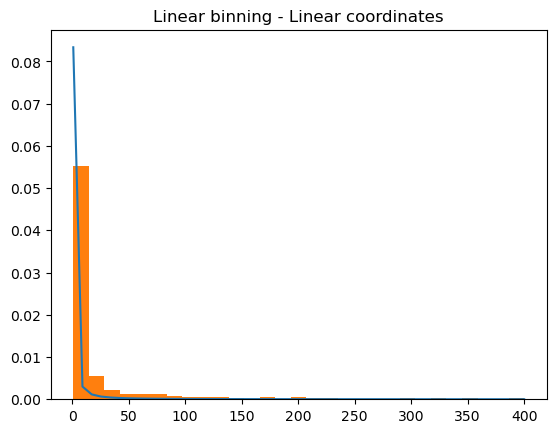

In [9]:
bins_lin = np.linspace(start = 1, stop = 400, num = NUMBER_OF_BINS) 

# Plotting the reference line
x = np.linspace(start = 1, stop = 400)
y = pow(x,-3/2)*1/12 # Scaled by 1/12 for aesthetic purposes
plt.plot(x,y)

# Plotting the histogram using linear binning, linear coordinates
plt.hist(x_gen, bins=bins_lin, density=True)
plt.title("Linear binning - Linear coordinates")
plt.plot()

Text(0.5, 1.0, 'Linear binning - Log coordinates')

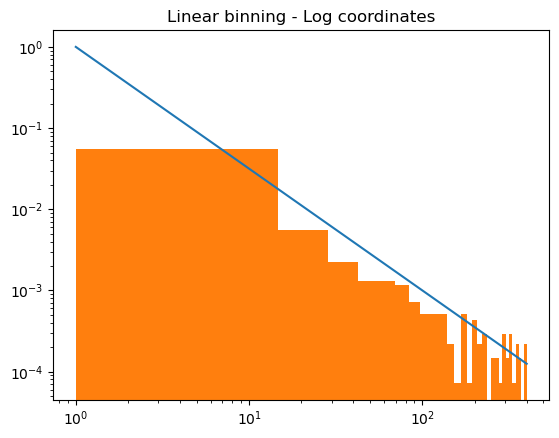

In [10]:

# Plotting the reference line
fig = plt.subplot()
x = np.linspace(start = 1, stop = 400)
y = pow(x,-3/2)
fig.plot(x,y)
fig.set_xscale('log')
fig.set_yscale('log')

# Plotting the histogram using linear binning, log coordinates
ax = plt.subplot()
ax.hist(x_gen, bins=bins_lin, density=True)
ax.set_xscale('log')
ax.set_yscale('log')

plt.title("Linear binning - Log coordinates")


#### c) Mid-point of Linear binning

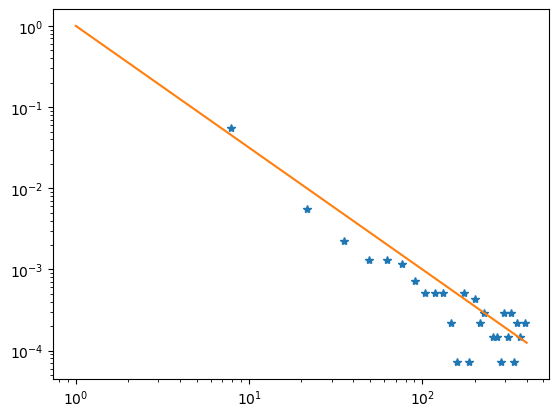

In [11]:
# Edges -> Center -> Plot
count,edges = np.histogram(x_gen, bins_lin, density = True)
centers = 0.5*(edges[1:] + edges[:-1])
ax2 = plt.subplot()
ax2.set_xscale('log')
ax2.set_yscale('log')

plt.plot(centers,count,'*')

# Plotting the reference line
fig = plt.subplot()
x = np.linspace(start = 1, stop = 400)
y = pow(x,-3/2)
fig.plot(x,y)
fig.set_xscale('log')
fig.set_yscale('log')


#### d) Mid point of Log binning

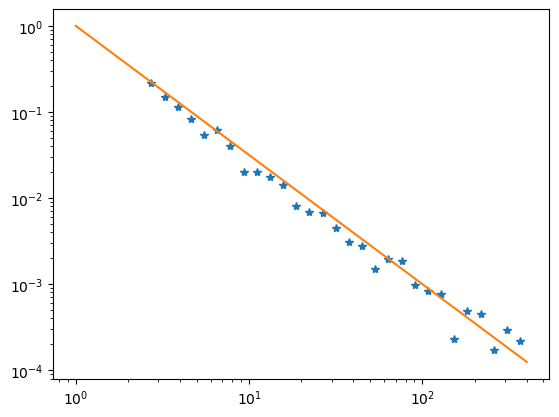

In [12]:
bins_log = np.logspace(start = np.log10(2.5), stop = np.log10(400), num = NUMBER_OF_BINS)

# Edges -> Center -> Plot
count,edges = np.histogram(x_gen, bins_log, density = True)
centers = np.sqrt(edges[1:] * edges[:-1])
ax3 = plt.subplot()
ax3.set_xscale('log')
ax3.set_yscale('log')

plt.plot(centers,count,'*')

# Plotting the reference line
fig = plt.subplot()
x = np.logspace(start = np.log10(1), stop = np.log10(400))
y = pow(x,-3/2)
fig.plot(x,y)
fig.set_xscale('log')
fig.set_yscale('log')


#### e) Comparison between logarithmic and linear binning
- The distribution shown is less clumped at the tail (large values) and more even across orders of magnitude (10)
- Reveals a clean linear relationship on a log-log scale

#### f) 
Simulate pdf by rejection method is slower because it discards many points, required more loops and time to generate the same number of samples, while the inverse method is exact and accept all generated points. In addition, it takes time to make a rejection policy, which sometimes doesn't envelope the distribution too well, like the power law, leading to a higher rejection rate, which makes rejection method even slower. 